In [1]:
import os
import sys

# Move up one directory from 'notebooks' to 'root_dir' and add it to python path
root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import torch.nn.functional as F
import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from src.mpc_l import PCLayer
from src.mpc_trainer import PCTrainer, PCTrainingArguments

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "mps")
print(f'using {device}')

using mps


In [2]:
# data
n_train = 10000
n_val = 500
n_test = 1000

transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: torch.flatten(x))])
dataset_train = datasets.MNIST('../data', download=True, train=True, transform=transform)
dataset_eval = datasets.MNIST('../data', download=True, train=False, transform=transform)

# randomly sample train and evaluation subsets
train_dataset = torch.utils.data.Subset(dataset_train, random.sample(range(len(dataset_train)), n_train))
val_dataset, test_dataset, _ = torch.utils.data.random_split(dataset_eval, [n_val, n_test, len(dataset_eval) - n_val - n_test])

print(f'# train: {len(train_dataset)}, # val: {len(val_dataset)}, # test: {len(test_dataset)}')

# train: 10000, # val: 500, # test: 1000


In [3]:
class BidirectionalPC(nn.Module):
    def __init__(self, alpha_up=1., alpha_down=1., pc_energy_fn=None, sample_fn=None):
        super(BidirectionalPC, self).__init__()
        
        if pc_energy_fn is None:
            pc_energy_fn =  lambda inputs: 0.5 *(inputs['mu'] - inputs['x'])**2
        
        if sample_fn is None:
            sample_fn = lambda inputs: inputs['mu'].detach().clone()


        # pc layer shared by up and down model
        self.pcs = [
            PCLayer(),
            PCLayer()
        ]
        
        self.activation = nn.ReLU()

        # up model
        self.model_up = nn.Sequential(
            nn.Linear(784, 256),
            self.pcs[0],
            self.activation,
            nn.Linear(256, 256),
            self.pcs[1],
            self.activation,
            nn.Linear(256, 10),
        )
        # down model
        self.model_down = nn.Sequential(
            nn.Linear(10, 256),
            self.pcs[1],
            self.activation,
            nn.Linear(256, 256),
            self.pcs[0],
            self.activation,
            nn.Linear(256, 784),
        )

        self._alpha_up = alpha_up
        self._alpha_down = alpha_down
    
    def get_energies(self):
        return [pc._energy.clone() for pc in self.pcs]

    def set_energies(self, energies):
        for i, energy in enumerate(energies):
            self.pcs[i]._energy = energy

    def forward(self, input):
        x = input[0]    # image
        y = input[1]    # label
        # get energies for up (this also initialises the latent layers)
        out_up = self.model_up(x)
        energy_up = self.get_energies()
        # get energies for down 
        out_down = self.model_down(y)
        energy_down = self.get_energies()
        # add the energies of the up and down model
        energy = [self._alpha_down*e_down + self._alpha_up*e_up  for (e_up, e_down) in zip(energy_up, energy_down)]
        self.set_energies(energy)
        return out_up, out_down


def test(model, dataset, batch_size=1000):
    model.eval()
    test_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False)
    correct = 0
    total = 0
    for data, label in test_loader:
        data, label = data.to(device), label.to(device)
        pred = model.model_up(data)
        _, predicted = torch.max(pred, -1)
        total += label.size(0)
        correct += (predicted == label).sum().item()
    model.train()
    return round(correct / total, 4)

In [4]:
alpha_up = 1.0  # scaling factor of the up model
alpha_down = 0.0001    # scaling factor of the down model

# get model
model = BidirectionalPC(alpha_down=alpha_down, alpha_up=alpha_up)
model.train()
model.to(device)


# loss function
mse = nn.MSELoss(reduction="sum")
def loss_fn(output, target):
    output_up, output_down = output
    target_up, target_down = target
    error_up = mse(output_up, target_up) * alpha_up
    error_down = mse(output_down, target_down) * alpha_down
    return error_up + error_down

In [5]:
T = 20                             # number of inference iterations
update_x_at = 'all'                 # update latent state x at every iteration
optimizer_x_fn = optim.SGD         # optimizer for latent state x
optimizer_x_kwargs = {'lr': 0.01}    # optimizer parameters for latent state x
update_p_at = 'last'                # update parameters p at the last iteration
optimizer_p_fn = optim.Adam          # optimizer for parameters p
optimizer_p_kwargs = {"lr": 1e-2, "weight_decay":0.} # optimizer parameters for parameters p
plot_progress_at = []            # plot progress every inference iterations

args = PCTrainingArguments(
	T = 20,                             # number of inference iterations
	optimizer_x_cls = optim.SGD,         # optimizer for latent state x
	optimizer_x_kwargs = {'lr': 0.01},    # optimizer parameters for latent state x
	update_p_at = 'last',                # update parameters p at the last iteration
	optimizer_p_cls = optim.Adam,          # optimizer for parameters p
	optimizer_p_kwargs = {"lr": 1e-2, "weight_decay":0.}, # optimizer parameters for parameters p
	device=device
)

trainer = PCTrainer(
    model, 
    args=args,
    loss_fn=loss_fn
)

Epoch 0 - Val accuracy: 0.114


Epoch 10: 100%|██████████| 20/20 [00:01<00:00, 10.98it/s, acc=0.946, energy=4.208, loss=26.679]


test acc: 0.956


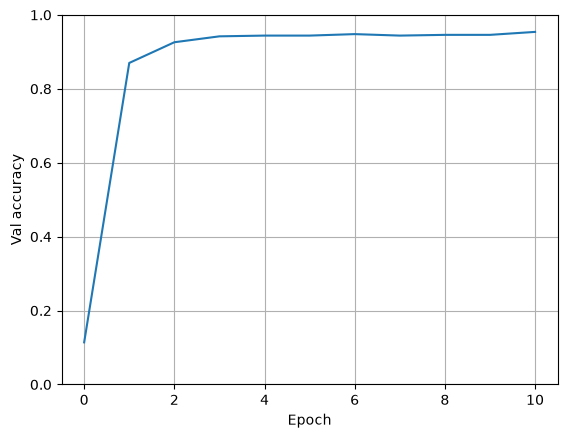

In [ ]:
n_epochs = 10
batch_size = 500
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)

model.train()
for layer in trainer.pc_layers():
    layer.train()

val_acc = {0: test(model, val_dataset)}
print(f"Epoch 0 - Val accuracy: {val_acc[0]:.3f}")

for epoch in range(n_epochs):
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    for data, label in pbar:
        data = data.to(device)
        label = label.to(device)
        labels_one_hot = F.one_hot(label, num_classes=10).float()

        inputs = (data, labels_one_hot)                 # model.forward
        targets = (labels_one_hot, data)                # loss_fn

        logs = trainer.training_step(inputs, targets)

        pbar.set_postfix(
            loss=f"{logs['loss']:.3f}",
            energy=f"{logs['energy']:.3f}",
            acc=f"{val_acc[epoch]:.3f}",
        )

    val_acc[epoch + 1] = test(model, val_dataset)
    pbar.set_description(f"Epoch {epoch+1} - Val accuracy: {val_acc[epoch+1]:.3f}")

print("test acc:", test(model, test_dataset))

plt.plot(list(val_acc.keys()), list(val_acc.values()))
plt.xlabel("Epoch")
plt.ylabel("Val accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

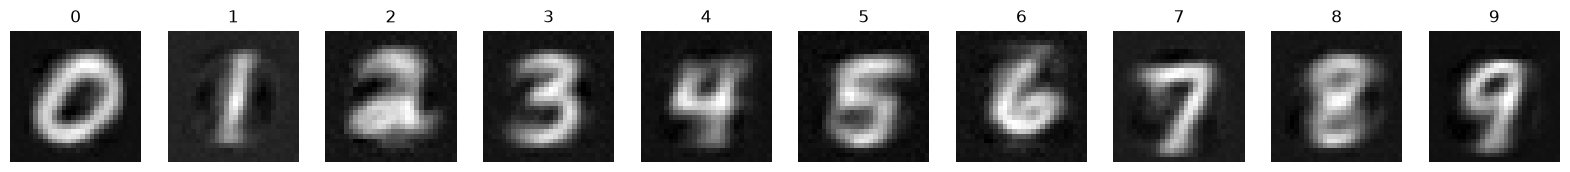

In [7]:
# generate images
model.eval()

imgs = []
for i in (range(10)):
    input = torch.zeros(1, 10)
    input[0, i] = 1
    input = input.to(device)

    img = model.model_down(input)
    imgs.append(img.cpu().detach().sigmoid().numpy().reshape(28, 28))

# show 10 images one for each digit
fig, ax = plt.subplots(1, 10, figsize=(20, 2))
for i in range(10):
    ax[i].imshow(imgs[i], cmap='gray')
    ax[i].axis('off')
    ax[i].set_title(f'{i}')

plt.show()